        # How does each rule score on the thirteen weeks it never saw, and which way is each wrong?

        **Week 4, Friday, chapter 2 of 3.** **The ticket.** Flipkart, the Lucknow fulfilment centre (FC), the warehouse where orders are packed
and shipped. The centre has 104 weeks of outbound shipments, the weeks beginning Monday 30 September
2024 to Monday 21 September 2026. Diwali fell on Thursday 31 October 2024 and Monday 20 October 2025,
and falls on Sunday 8 November 2026; the festive sale runs in the third and second weeks before
Diwali's week. A packer packs about 120 shipments a shift, and a packer-shift is one packer working
one shift. The planner must book packer shifts for the eight weeks beginning 12 October to 30
November 2026, the festive window. A vendor's demand model promises the window 22 percent above the
same weeks last year; finance's rule is those weeks plus 4 percent: eighteen percentage points apart.
A late shipment costs Rs 25 (assumed, Rs 15 to 40). A spare shipment, planned for and never shipped,
leaves part of a packer-shift idle: Rs 650 a shift (assumed, Rs 500 to 800) over 120 shipments, Rs
5.42 a shipment. Illustrative case: the company is real, the situation and the data are synthetic, built for this class.

        Chapter 1 found the peak two weeks before Diwali's week and showed that a copy of the same
        calendar week lands it a week late in 2025. This notebook scores every rule, and the
        vendor's curve, on weeks none of them saw.

        **Who needs the answer.** The FC planner, who may send only a forecast that has beaten the
        house bot on weeks it never saw, and the regional operations head, who must say yes or no
        to the vendor's plus 22 percent before a shift is booked.

        **The questions on the way.** Which weeks do we hide, and from which week do we forecast?
        What does each rule forecast for them? Which rule scores best? What did the vendor score,
        and what does its fit to the past say? Which way is each rule wrong, and what does that
        cost in rupees? Does the score match the printed error table?

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)

weekly = pd.read_csv("../data/C2_W04_D05_weekly_shipments_STUDENT.csv", parse_dates=["week_start"])
vendor = pd.read_csv("../data/C2_W04_D05_vendor_forecast_STUDENT.csv", parse_dates=["week_start"])
y = weekly.set_index("week_start").shipments
split = 91                                    # the row of the first hidden week, 29 Jun 2026
train, hold = y.iloc[:split], y.iloc[split:]  # the weeks the rules may see, and the weeks they forecast
print(f"training weeks: {len(train)}, {train.index[0].date()} to {train.index[-1].date()}")
print(f"hidden weeks: {len(hold)}, {hold.index[0].date()} to {hold.index[-1].date()}")
print(vendor.kind.value_counts().to_string())
check("the hidden weeks are the latest ones", hold.index[-1] == y.index[-1])
check("no week is lost or counted twice", len(train) + len(hold) == len(y))
check("the vendor's rows for the hidden weeks are forecasts made from 22 June, never fits",
      set(vendor.set_index("week_start").loc[hold.index, "kind"]) == {"holdout"})

training weeks: 91, 2024-09-30 to 2026-06-22
hidden weeks: 13, 2026-06-29 to 2026-09-21
kind
fitted      91
holdout     13
forecast    10
PASS the hidden weeks are the latest ones
PASS no week is lost or counted twice
PASS the vendor's rows for the hidden weeks are forecasts made from 22 June, never fits


## Which weeks do we hide, and how is the score counted?

The plan books eight weeks ahead; that reach is the **horizon**. The test hides at least as
many weeks at the end of the data: the last thirteen, 29 June to 21 September 2026, the
**hidden weeks** (also called the hold-out, or the test set). The rules may see only the 91
**training weeks** before them, and every rule forecasts all thirteen from the last of
those, the week of 22 June 2026, called the **origin**. The vendor's file labels its rows
three ways: **fitted** rows are its answers for weeks it was built on, **holdout** rows its
forecasts for the hidden weeks, made from 22 June, and **forecast** rows the weeks ahead.

The score is the **mean absolute error** (MAE): each week's miss in shipments, sign dropped,
averaged. Its cousin, the **mean absolute percentage error** (MAPE), averages each miss as a
percent of what shipped: it compares centres of different sizes, and it divides by the
actual, so a week that ships almost nothing makes it explode. Three hidden weeks with misses
of 10, 5 and 10 (invented) score an MAE of 8.3.

In [2]:
misses = [10, -5, 10]                          # three hidden weeks' misses (invented)
mae_toy = sum(abs(m) for m in misses) / len(misses)
print(f"MAE: {mae_toy:.1f}")
check("the toy MAE is 8.3", round(mae_toy, 1) == 8.3)

MAE: 8.3
PASS the toy MAE is 8.3


## What does each rule forecast for the hidden weeks?

Each rule in one line, all from the week of 22 June 2026. **Naive** repeats that week.
**Drift** draws the straight line from the first week through that week and extends it.
**The house bot** copies the week 52 weeks back. **Finance's rule** is the house bot plus 4
percent. **Festival-aligned**, from five weeks before Diwali's week to four after, copies
the week at the same distance from last year's Diwali; on every other week it copies the
same calendar week; then it adds the 4 percent a year the centre grew. No hidden week falls
in that stretch around a Diwali, so on these weeks festival-aligned and finance's rule are
one rule.

Two pieces of code are new. `y.shift(52)` slides the whole series down 52 rows, so each
week's row holds the value from 52 weeks earlier. `h` counts the weeks ahead of the origin,
1 to 13. The growth line compares the latest 39 training weeks, 29 September 2025 to 22
June 2026, with the same 39 weeks a year earlier.

In [3]:
origin = train.index[-1]                                         # the last week the rules may see
h = pd.Series(range(1, len(hold) + 1), index=hold.index)         # weeks ahead: 1, 2, 3 and so on
slope = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)       # drift: the average change a week
growth = y.iloc[52:split].sum() / y.iloc[0:split - 52].sum() - 1  # a year's growth on the same weeks
factor = round(1 + growth, 2)                                     # 1.04, the same 4 percent finance uses
last_year = y.shift(52).loc[hold.index]                           # each hidden week's same week last year
rules = pd.DataFrame({
    "naive": train.iloc[-1],
    "drift": (train.iloc[-1] + h * slope).round(),
    "house bot": last_year,
    "finance": (last_year * 1.04).round(),
    "festival-aligned": (last_year * factor).round(),
}).astype(int)
nearest = min(abs((d - pd.Timestamp("2026-11-02")).days) // 7 for d in hold.index)
print(f"origin {origin.date()}, drift {slope:.0f} a week, growth a year {growth:.1%}")
print(f"the hidden week nearest Diwali 2026 is {nearest} weeks before it")
print(rules.head(3).to_string())
check("the growth the training weeks show rounds to 4 percent", factor == 1.04)
check("no hidden week falls in the stretch around a Diwali", nearest > 5)

origin 2026-06-22, drift 70 a week, growth a year 4.0%
the hidden week nearest Diwali 2026 is 6 weeks before it
             naive   drift  house bot  finance  festival-aligned
week_start                                                      
2026-06-29  218300  218370     198800   206752            206752
2026-07-06  218300  218440     192400   200096            200096
2026-07-13  218300  218510     194200   201968            201968
PASS the growth the training weeks show rounds to 4 percent
PASS no hidden week falls in the stretch around a Diwali


**Predict before you run.** Which rule has the lowest MAE on the thirteen hidden weeks?

a) naive
b) drift
c) the house bot
d) festival-aligned, tied with finance's rule

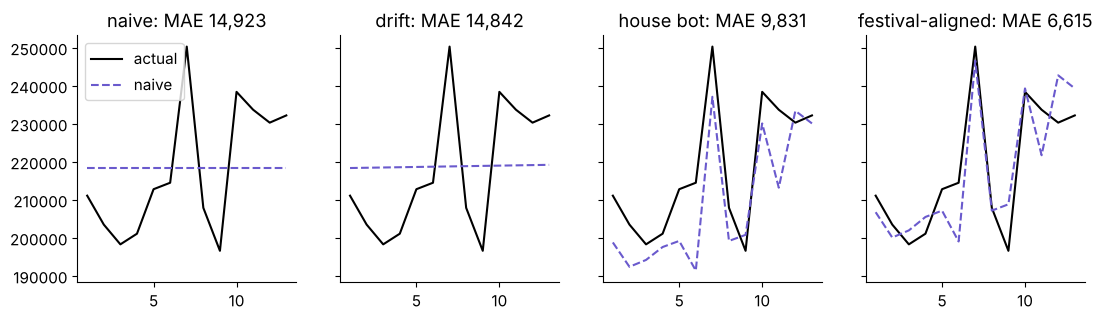

finance              6615
festival-aligned     6615
house bot            9831
drift               14842
naive               14923
PASS festival-aligned and finance tie
PASS the house bot beats naive and drift


In [4]:
scores = pd.Series({name: (rules[name] - hold).abs().mean()     # each rule's misses, signs dropped, averaged
                    for name in rules.columns}).round().astype(int).sort_values()
weeks_ahead = range(1, len(hold) + 1)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, name in zip(axes, ["naive", "drift", "house bot", "festival-aligned"]):
    ax.plot(weeks_ahead, hold.values, color="black", label="actual")
    ax.plot(weeks_ahead, rules[name].values, ls="--", color="slateblue", label=name)
    ax.set_title(f"{name}: MAE {scores[name]:,}")
axes[0].legend()
plt.show()
print(scores.to_string())
check("festival-aligned and finance tie", scores["festival-aligned"] == scores["finance"])
check("the house bot beats naive and drift", scores["house bot"] < min(scores["naive"], scores["drift"]))

**What happened.** The answer is d. Festival-aligned and finance's rule tie at 6,615
shipments a week, the house bot scores 9,831, and naive and drift miss by 14,923 and
14,842. The house bot beats naive because it carries the August sale and the summer dip
from last year; it loses to the 4 percent rules because a growing series makes last year's
week too low. The tie is honest: on weeks this far from Diwali the two rules are the same
arithmetic.

**Predict before you run.** The vendor's sponsor says the curve sits within 2 percent of
every past week. On the thirteen hidden weeks, how does it score against the house bot's
9,831?

a) far below the bot, since it fits the past best
b) about the same as the bot
c) above the bot: it misses by more

**Your turn.** Score the vendor on the same hidden weeks. Type these lines into the empty
cell below and run it:

```python
v = vendor.set_index("week_start").vendor_shipments
print(f"vendor MAE: {(v.loc[hold.index] - hold).abs().mean():,.0f}")
```

## What does the vendor's fit to the past say about its forecast?

**The plausible wrong answer.** The vendor's sponsor, the manager who brought the model in,
says: "The curve sits within 2 percent of every week of history, so its plus 22 percent can
be trusted." A fit is drawn through weeks the model has seen; a forecast is made for weeks
it has not. Within 2 percent is the sponsor's claim; the cell below measures the worst
fitted week.

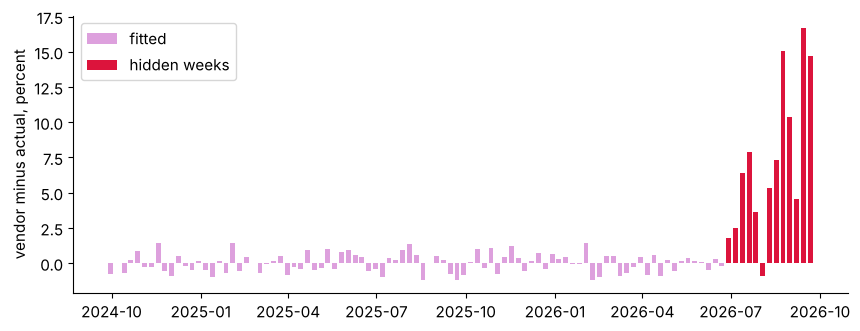

largest miss on the 91 fitted weeks: 1.4%
vendor MAE on the hidden weeks: 16,400
too high by 3.6% on average in hidden weeks 1 to 6, 11.5% in weeks 8 to 13
PASS the fit stays within 2 percent
PASS the vendor's MAE is at least 30 percent above festival-aligned


In [5]:
v = vendor.set_index("week_start").vendor_shipments
fitted = vendor[vendor.kind == "fitted"].set_index("week_start").vendor_shipments
fit_gap = ((fitted - y.loc[fitted.index]) / y.loc[fitted.index]).abs().max()   # the worst fitted week
hold_gap = (v.loc[hold.index] - hold) / hold                                    # each hidden week, as a share
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(fitted.index, (fitted - y.loc[fitted.index]) / y.loc[fitted.index] * 100, width=5, color="plum", label="fitted")
ax.bar(hold.index, hold_gap * 100, width=5, color="crimson", label="hidden weeks")
ax.set_ylabel("vendor minus actual, percent")
ax.legend()
plt.show()
print(f"largest miss on the {len(fitted)} fitted weeks: {fit_gap:.1%}")
vendor_mae = (v.loc[hold.index] - hold).abs().mean()                            # the same measure as the rules
print(f"vendor MAE on the hidden weeks: {vendor_mae:,.0f}")
print(f"too high by {hold_gap.iloc[:6].mean():.1%} on average in hidden weeks 1 to 6, "
      f"{hold_gap.iloc[-6:].mean():.1%} in weeks 8 to 13")
check("the fit stays within 2 percent", fit_gap <= 0.02)
check("the vendor's MAE is at least 30 percent above festival-aligned",
      vendor_mae >= 1.3 * scores["festival-aligned"])

**Why it is wrong.** The answer is c. The vendor never misses its fitted weeks by more than 1.4 percent, and
it misses the hidden weeks by 16,400 a week, 148 percent worse than festival-aligned and 67
percent worse than the house bot. The check is the one the room fixed before scoring: error
on the weeks it never saw. The fix is to send nothing to the plan that loses to the house
bot there.

## Which way is each rule wrong, and what does each direction cost?

**Predict before you run.** Which rule's misses cost the least once a late shipment costs
Rs 25 and a spare shipment Rs 5.42?

a) festival-aligned, since its MAE is lowest
b) the vendor
c) the house bot
d) naive

                    MAE  weeks too high  spare Rs lakh  late Rs lakh  cost Rs lakh
rule                                                                              
vendor            16400              12           11.4           0.5          11.9
finance            6615               6            2.2          11.3          13.5
festival-aligned   6615               6            2.2          11.3          13.5
drift             14842               8            5.6          22.4          28.0
naive             14923               8            5.4          23.4          28.8
house bot          9831               2            0.4          30.1          30.5


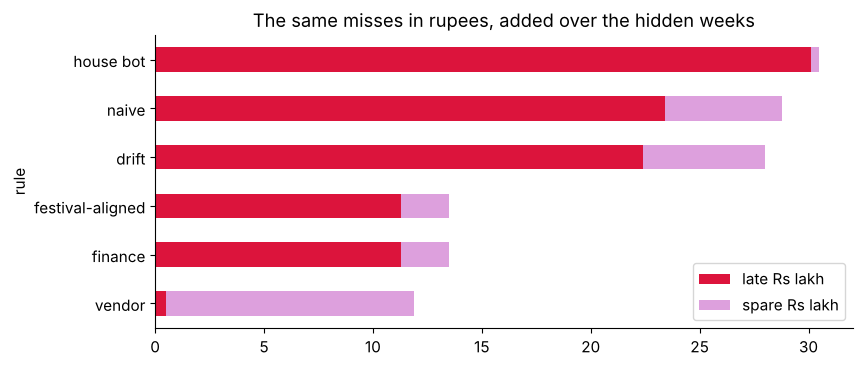

PASS the vendor errs high on most hidden weeks
PASS on these hidden weeks, priced, the vendor costs less than festival-aligned


In [6]:
rules["vendor"] = v.loc[hold.index]
rows = []
for name in rules.columns:
    miss = rules[name] - hold                                     # forecast minus actual: positive is too high
    spare_rs = miss[miss > 0].sum() * 650 / 120                    # planned and never shipped, Rs 5.42 each
    late_rs = -miss[miss < 0].sum() * 25                           # shipped late, Rs 25 each
    rows.append({"rule": name, "MAE": round(miss.abs().mean()), "weeks too high": int((miss > 0).sum()),
                 "spare Rs lakh": round(spare_rs / 100_000, 1),     # 100,000 rupees make a lakh
                 "late Rs lakh": round(late_rs / 100_000, 1),
                 "cost Rs lakh": round((spare_rs + late_rs) / 100_000, 1)})
priced = pd.DataFrame(rows).set_index("rule").sort_values("cost Rs lakh")
print(priced.to_string())
priced[["late Rs lakh", "spare Rs lakh"]].sort_values("late Rs lakh").plot.barh(stacked=True,
    color=["crimson", "plum"], title="The same misses in rupees, added over the hidden weeks")
plt.show()
check("the vendor errs high on most hidden weeks", priced.loc["vendor", "weeks too high"] > len(hold) / 2)
check("on these hidden weeks, priced, the vendor costs less than festival-aligned",
      priced.loc["vendor", "cost Rs lakh"] < priced.loc["festival-aligned", "cost Rs lakh"])

**What happened.** The answer is b, and it is the uncomfortable result. The vendor's
misses cost Rs 11.9 lakh, festival-aligned's Rs 13.5 lakh, the house bot's Rs 30.5 lakh,
each added over the thirteen weeks. The vendor errs high on 12 of 13 weeks, and a spare
shipment costs Rs 5.42 against Rs 25 for a late one, so its bigger misses are the cheaper
kind. The house bot's misses are the dear kind: 11 of its 13 weeks are too low, which is why
it costs more than naive while scoring a lower MAE.

This says that erring high pays at these costs. It does not hand the vendor the plan:
nobody chose how far high it runs, it runs higher the further ahead it looks (3.6 percent
too high in hidden weeks 1 to 6, 11.5 percent in weeks 8 to 13), and no hidden week holds a
festival, where the vendor copies the wrong weeks. Chapter 3 raises festival-aligned by an
amount the two costs choose instead.

## Does the score match the printed error table?

A second route to the same number: print festival-aligned's thirteen misses as a table and
average them by hand.

In [7]:
table = pd.DataFrame({"actual": hold, "festival-aligned": rules["festival-aligned"]})
table["miss"] = table["festival-aligned"] - table["actual"]        # positive: too high
print(table.to_string())
by_hand = sum(abs(m) for m in table["miss"]) / len(table)
print(f"too high: {table.miss[table.miss > 0].sum():,}; too low: {-table.miss[table.miss < 0].sum():,}")
print(f"MAE from the printed misses: {by_hand:,.0f}")
check("the printed table gives the same MAE", round(by_hand) == scores["festival-aligned"])

            actual  festival-aligned   miss
week_start                                 
2026-06-29  211100            206752  -4348
2026-07-06  203500            200096  -3404
2026-07-13  198300            201968   3668
2026-07-20  201100            205504   4404
2026-07-27  212800            207168  -5632
2026-08-03  214500            199056 -15444
2026-08-10  250300            246584  -3716
2026-08-17  207900            207168   -732
2026-08-24  196600            208832  12232
2026-08-31  238400            239304    904
2026-09-07  233700            221728 -11972
2026-09-14  230300            242736  12436
2026-09-21  232200            239304   7104
too high: 40,748; too low: 45,248
MAE from the printed misses: 6,615
PASS the printed table gives the same MAE


## How would you answer "how do you evaluate a forecast?" in an interview?

Hide the latest weeks, at least as many as the plan's horizon, and forecast them from one
origin. Fix the error measure before anyone scores, in the business's unit: shipments,
then rupees. Compare every candidate with naive and the house bot, and send nothing that
loses to them. Report which way the misses run, because a late shipment and a spare one
cost different amounts. The trap the interviewer fishes for is judging by the fit.

## What did chapter 2 answer?

- **Which weeks are hidden?** The last thirteen, 29 June to 21 September 2026, forecast
  from the week of 22 June 2026.
- **Which rule scores best?** Festival-aligned and finance's rule, tied at 6,615 a week;
  the house bot 9,831; naive 14,923; drift 14,842.
- **What did the vendor score?** 16,400, after fitting history within 1.4 percent: fit is
  not forecast.
- **Which way is each wrong, and at what cost?** The vendor errs high on 12 of 13 weeks and
  costs Rs 11.9 lakh; festival-aligned Rs 13.5 lakh; the house bot errs low and costs Rs
  30.5 lakh.
- **Does the table agree?** Yes, 6,615 from the printed misses.
- **Is festival-aligned good enough?** Good enough is a claim about the decision: a better
  forecast is worth having only if it would book different shifts. Chapter 3 asks where the
  festival falls this year and how far above the forecast the plan should sit, which these
  weeks cannot test.